<a href="https://colab.research.google.com/github/halynazhabchyk/nlp_labs/blob/main/NLP_5_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Практикум №5
#РІШЕННЯ ЗАДАЧІ POS-ТЕГУВАННЯ ЗА ДОПОМОГОЮ ЗГОРТКОВИХ НЕЙРОННИХ МЕРЕЖ

Мета роботи: Ознайомитися з концепцією POS-тегування (визначення
частин мови слів) та його важливістю в обробці тексту. Вивчити базові
принципи використання згорткових нейронних мереж (CNN) для аналізу
послідовностей тексту. Реалізувати модель CNN для задачі POS-тегування.

POS-тегування (Part of Speech Tagging) – це задача автоматичного
визначення граматичної категорії кожного слова в реченні. POS-тегування є фундаментальним кроком у багатьох задачах
обробки природної мови (NLP).

Розпочинаємо з імпорту сновних бібліотек

In [ ]:
!pip install pyconll

In [ ]:
import os
import requests
from torch.utils.data import TensorDataset
import pyconll
from collections import Counter
import torch

Для вирішення задачі будемо застосовувати Корпус (UD_Ukrainian-IU), який цілком
підходить для задачі POS-тегування для української мови.

train: Навчальні дані.
dev: Дані для валідації.
test: Тестові дані.

In [ ]:
# URL-адреси для завантаження даних
DATASETS = {
 "train":"https://raw.githubusercontent.com/UniversalDependencies/UD_Ukrainian-IU/master/uk_iu-ud-train.conllu",
 "dev":"https://raw.githubusercontent.com/UniversalDependencies/UD_Ukrainian-IU/master/uk_iu-ud-dev.conllu",
 "test":"https://raw.githubusercontent.com/UniversalDependencies/UD_Ukrainian-IU/master/uk_iu-ud-test.conllu"
}


Реалізуємо функцію для завантаження корпусу

In [ ]:
def download_corpus(url, save_path):
    if not os.path.exists(save_path):
        print(f"Завантаження {save_path}...")
        response = requests.get(url)
        with open(save_path, "w", encoding="utf-8") as f:
            f.write(response.text)
        print(f"{save_path} завантажено.")
    else:
        print(f"{save_path} вже завантажено.")
    return save_path

Завантаження всіх частин корпусу

In [ ]:
corpora_paths = {}
for split, url in DATASETS.items():
 save_path = f"ukrainian_pos_{split}.conllu"
 corpora_paths[split] = download_corpus(url, save_path)

Завантаження ukrainian_pos_train.conllu...
ukrainian_pos_train.conllu завантажено.
Завантаження ukrainian_pos_dev.conllu...
ukrainian_pos_dev.conllu завантажено.
Завантаження ukrainian_pos_test.conllu...
ukrainian_pos_test.conllu завантажено.


Завантажимо данні у форматі CoNLL-U

In [ ]:
train_data = pyconll.load_from_file(corpora_paths["train"])
val_data = pyconll.load_from_file(corpora_paths["dev"])
test_data = pyconll.load_from_file(corpora_paths["test"])


Перевіряємо тексти

In [ ]:
print(f"Train: {len(train_data)} речень")
print(f"Dev: {len(val_data)} речень")
print(f"Test: {len(test_data)} речень")

Train: 5521 речень
Dev: 673 речень
Test: 898 речень


In [ ]:
for i, sentence in enumerate(train_data[:2]):
 print(f"Речення {i+1}:")
 for token in sentence:
  print(f"{token.form}\t{token.upos}")
  print("\n")

Речення 1:
У	ADP


домі	NOUN


римського	ADJ


патриція	NOUN


Руфіна	PROPN


була	VERB


прегарна	ADJ


фреска	NOUN


,	PUNCT


зображення	NOUN


Венери	PROPN


та	CCONJ


Адоніса	PROPN


.	PUNCT


Речення 2:
Якось	ADV


зібралися	VERB


у	ADP


нього	PRON


,	PUNCT


ховаючися	VERB


від	ADP


переслідувань	NOUN


,	PUNCT


одновірці	NOUN


дружини	NOUN


–	PUNCT


християнки	NOUN


.	PUNCT




In [ ]:
max_sentence_length = max(len(sentence) for sentence in train_data)
max_token_length = max(len(token.form) for sentence in train_data for
token in sentence)
print(f"Максимальна довжина речення: {max_sentence_length}")
print(f"Максимальна довжина токена: {max_token_length}")

Максимальна довжина речення: 197
Максимальна довжина токена: 115


Далі реалізуємо функційї для завантаження та збереження моделі

In [ ]:
def save_model(model, filepath):

 """Збереження моделі в файл"""

 torch.save(model.state_dict(), filepath)
 print(f"Модель збережено в {filepath}")

In [ ]:
def load_model(model, filepath, device="cpu"):

 """Завантаження моделі з файлу"""
 model.load_state_dict(torch.load(filepath, map_location=device))
 model.to(device)
 print(f"Модель завантажено з {filepath}")

Наступний крок- побудова словника із підрахунком частоти кожного символу

In [ ]:

def build_char_vocab(data):
    char_counter = Counter()  # Лічильник для підрахунку символів
    for sentence in data:     # Проходимо по всіх реченнях у корпусі
        for token in sentence:  # Для кожного слова в реченні
            char_counter.update(token.form)  # Додаємо символи слова у лічильник

    # Створюємо словник символів: <PAD> отримує індекс 0, решта символів - індекси з 1
    char_vocab = {"<PAD>": 0, **{char: idx + 1 for idx, char in enumerate(sorted(char_counter.keys()))}}
    return char_vocab

In [ ]:
char_vocab = build_char_vocab(train_data)

print(f"Розмір словника символів: {len(char_vocab)}")
# Вивід розміру словника: Кількість унікальних символів, включаючи
# <PAD>.
print("Перші 10 символів у словнику:")

for char, idx in list(char_vocab.items())[:10]:
 print(f"Символ: '{char}' -> Номер: {idx}")

Розмір словника символів: 190
Перші 10 символів у словнику:
Символ: '<PAD>' -> Номер: 0
Символ: ' ' -> Номер: 1
Символ: '!' -> Номер: 2
Символ: '"' -> Номер: 3
Символ: '#' -> Номер: 4
Символ: '$' -> Номер: 5
Символ: '%' -> Номер: 6
Символ: '&' -> Номер: 7
Символ: ''' -> Номер: 8
Символ: '(' -> Номер: 9


Проаналізуємо частоту символів

In [ ]:
char_counter = Counter()
for sentence in train_data:
 for token in sentence:
  char_counter.update(token.form)
print("\nНайчастотніші символи:")
for char, count in char_counter.most_common(10):
 print(f"Символ: '{char}' -> Частота: {count}")


Найчастотніші символи:
Символ: 'о' -> Частота: 38005
Символ: 'а' -> Частота: 33855
Символ: 'н' -> Частота: 27248
Символ: 'и' -> Частота: 26678
Символ: 'і' -> Частота: 23632
Символ: 'в' -> Частота: 20986
Символ: 'т' -> Частота: 20490
Символ: 'е' -> Частота: 18769
Символ: 'р' -> Частота: 18506
Символ: 'с' -> Частота: 16068


Далі побудуємо словник для частин мови (POS-тегів), який
перетворює текстові мітки на числа.  Він працює так само, як і для
символів, тільки тепер він пов’язує назви частин мови (наприклад, "NOUN"
для іменників) із числами.


In [ ]:
def build_pos_vocab(data):
 pos_tags = sorted({token.upos for sentence in data for token in sentence
if token.upos is not None})
 pos_vocab = {pos: idx + 1 for idx, pos in enumerate(pos_tags)} #Починаємо з 1
 pos_vocab["<PAD>"] = 0 # Фіктивний тег
 return pos_vocab

In [ ]:
pos_vocab = build_pos_vocab(train_data)
print(f"Розмір словника частин мови: {len(pos_vocab)}")
assert None not in pos_vocab

Розмір словника частин мови: 18


Необхідно також отримати приклади для  POS-тегів за якими модель буде їх передбачати

In [ ]:
def get_pos_examples(data, pos_vocab, num_examples=3):
    # Створюємо словник для прикладів по кожній частині мови
    pos_examples = {pos: [] for pos in pos_vocab.keys() if pos != "<PAD>"}

    # Проходимо по всіх реченнях у корпусі
    for sentence in data:
        for token in sentence:
            pos = token.upos  # Беремо частину мови слова
            # Додаємо слово до списку прикладів, якщо ще не зібрано достатньо
            if pos in pos_examples and len(pos_examples[pos]) < num_examples:
                pos_examples[pos].append(token.form)

    return pos_examples

In [ ]:
pos_examples = get_pos_examples(train_data, pos_vocab)
print("Приклади для кожного POS-тегу:")

for pos, examples in pos_examples.items():
 print(f"{pos}: {', '.join(examples)}")

Приклади для кожного POS-тегу:
ADJ: римського, прегарна, певні
ADP: У, у, від
ADV: Якось, одразу, негайно
AUX: було, би, був
CCONJ: та, Й, і
DET: свого, їх, одна
INTJ: Ні, Гей, Ого
NOUN: домі, патриція, фреска
NUM: сто, двох, тридцять
PART: ж, і, ж
PRON: нього, Це, вона
PROPN: Руфіна, Венери, Адоніса
PUNCT: ,, ., ,
SCONJ: як, Як, аніж
SYM: :), :wink2:, )
VERB: була, зібралися, ховаючися
X: et, cetera, Kapital’у


Наступним етапом зробимо перетворення корпусу в формат
необхідний для подальшої обробки під час навчання.

In [ ]:

def convert_to_tensors(data, char_vocab, pos_vocab, max_token_len, max_sent_len):
    num_sentences = len(data)

    # Тензор для символів: розміри [кількість речень, max довжина речення, max довжина токена]
    char_tensor = torch.zeros((num_sentences, max_sent_len, max_token_len), dtype=torch.long)

    # Тензор для POS-тегів: розміри [кількість речень, max довжина речення]
    pos_tensor = torch.zeros((num_sentences, max_sent_len), dtype=torch.long)

    for i, sentence in enumerate(data):
        for j, token in enumerate(sentence):
            if j >= max_sent_len:
                break  # Обмеження на довжину речення

            # Перетворюємо токен у список індексів символів
            token_chars = [char_vocab.get(char, 0) for char in token.form[:max_token_len]]

            # Записуємо індекси символів у тензор, заповнюючи відповідні позиції
            char_tensor[i, j, :len(token_chars)] = torch.tensor(token_chars)

            # Записуємо POS-тег токена
            pos_tensor[i, j] = pos_vocab.get(token.upos, 0)

    return char_tensor, pos_tensor

Обчислення максимальних довжин

In [ ]:
max_token_len = max(len(token.form) for sentence in train_data for token
in sentence)
max_sent_len = max(len(sentence) for sentence in train_data)

Підготовка тензорів для обробки

In [ ]:
train_char_tensor, train_pos_tensor = convert_to_tensors(train_data,
                                                        char_vocab,
                                                        pos_vocab,
                                                        max_token_len,
                                                        max_sent_len)

val_char_tensor, val_pos_tensor = convert_to_tensors(val_data,
                                                     char_vocab,
                                                     pos_vocab,
                                                     max_token_len,
                                                     max_sent_len)
test_char_tensor, test_pos_tensor = convert_to_tensors(test_data,
                                                       char_vocab,
                                                       pos_vocab,
                                                       max_token_len,
                                                       max_sent_len)

In [ ]:
print(f"Форма тензора символів: {train_char_tensor.shape}")
print(f"Форма тензора POS-тегів: {train_pos_tensor.shape}")

Форма тензора символів: torch.Size([5521, 197, 115])
Форма тензора POS-тегів: torch.Size([5521, 197])


Додаємо функцію для додавання колонок по краях тензора, оскільки ми працюватимемо зі згортковими мережами

In [ ]:
def add_special_columns(char_tensor):
 batch_size, max_sent_len, max_token_len = char_tensor.shape
 special_tensor = torch.zeros((batch_size, max_sent_len, max_token_len+ 2), dtype=torch.long)
 special_tensor[:, :, 1:-1] = char_tensor
 return special_tensor

Оновлюємо тензори символів

In [ ]:
train_char_tensor = add_special_columns(train_char_tensor)
val_char_tensor = add_special_columns(val_char_tensor)
test_char_tensor = add_special_columns(test_char_tensor)

In [ ]:
print(train_char_tensor[1][:5])
print(train_pos_tensor[1])
print(f"Оновлена форма тензора символів: {train_char_tensor.shape}")

tensor([[  0, 139, 150, 154, 157, 167,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0],
        [  0, 147, 171, 141, 156, 140, 151, 148, 157, 169,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0

Датасет у форматі CoNLL містить
речення, розбиті на токени (слова), причому кожен токен має
атрибути:


Слово (форма): фактичний текст слова, наприклад, "Київ".


Частина мови (POS-тег): Граматичний клас слова, наприклад,
"PROPN" (власна назва).


Інша інформація, наприклад, залежності чи леми, але ми фокусуємось
на POS-тегах.

Переходимо до створення згортокової мережі

Спочатку реалізуємо блок згортки

In [ ]:


class ConvBlock(nn.Module):
    def __init__(self, in_channels, kernel_size=3, dropout=0.1):
        super(ConvBlock, self).__init__()
        # Згортковий шар 1D з padding, щоб розмір вхідного сигналу зберігався
        self.conv = nn.Conv1d(in_channels, in_channels, kernel_size, padding=kernel_size // 2)
        self.dropout = nn.Dropout(dropout)  # Шар випадкового відсіву для регуляризації
        self.activation = nn.LeakyReLU(negative_slope=0.1)  # Активація LeakyReLU

    def forward(self, x):
        out = self.conv(x)        # Застосування згортки
        out = self.dropout(out)   # Випадкове відключення частини нейронів
        out = self.activation(out)  # Нелінійна активація
        return out

Далі створюємо клас згорткового шару із ResNet з'єднанням

In [ ]:

class ConvResNet(nn.Module):
    def __init__(self, in_channels, num_layers, kernel_size=3, dropout=0.1):
        super(ConvResNet, self).__init__()
        # Створюємо список згорткових блоків
        self.layers = nn.ModuleList([
            ConvBlock(in_channels, kernel_size, dropout) for _ in range(num_layers)
        ])

    def forward(self, x):
        # Прямий прохід через всі шари
        for layer in self.layers:
            out = layer(x)
            x = x + out  # ResNet-з'єднання (додаємо вхід до виходу)
        return x

Формуємо модель POS-тегування на основі символів.  основі моделі – обробка символів за
допомогою згорткових нейронних мереж (ConvResNet) із ResNetз'єднаннями.


Створюємо клас для формування ембендінг шару. Цей шар перетворює символи
(представлені індексами) на вектори певної розмірності

In [ ]:


class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super(TokenEmbedding, self).__init__()
        # Створюємо шар ембеддінгів
        self.embedding = nn.Embedding(vocab_size, embedding_dim)

    def forward(self, x):
        """
        Вхід: x - тензор розмірності [batch_size, max_sentence_len, max_token_len]
        """
        batch_size, max_sentence_len, max_token_len = x.size()

        # Об’єднуємо перші два виміри, щоб обробляти всі токени одночасно
        x = x.view(-1, max_token_len)  # [total_tokens, max_token_len]

        # Проходимо через шар ембеддінгів
        x = self.embedding(x)  # [total_tokens, max_token_len, embedding_dim]

        # Транспонуємо для згорткового модуля
        x = x.permute(0, 2, 1)  # [total_tokens, embedding_dim, max_token_len]
        return x


Повна модель POS-тегування

In [ ]:


class TokenPOSTagger(nn.Module):
    def __init__(self, vocab_size, labels_num, embedding_size=32,
                 num_res_layers=3, kernel_size=3, dropout=0.1):
        super().__init__()
        # Embedding-слой для символів
        self.token_embedding = TokenEmbedding(vocab_size, embedding_size)

        # Backbone: ConvResNet із ResNet-з'єднаннями
        self.backbone = ConvResNet(
            in_channels=embedding_size,
            num_layers=num_res_layers,
            kernel_size=kernel_size,
            dropout=dropout
        )

        # Max pooling для агрегації ознак по символам кожного токена
        self.global_pooling = nn.AdaptiveMaxPool1d(1)

        # Повнозв'язний шар для передбачення POS-тегів
        self.out = nn.Linear(embedding_size, labels_num)

    def forward(self, tokens):
        """
        Вхід:
        tokens - тензор розмірності [batch_size, max_sentence_len, max_token_len]
        """
        batch_size, max_sentence_len, max_token_len = tokens.shape

        # Ембеддинги символів для всіх токенів
        char_embeddings = self.token_embedding(tokens)  # [TotalTokens, EmbeddingDim, MaxTokenLen]

        # Згорткова обробка (ConvResNet)
        features = self.backbone(char_embeddings)  # [TotalTokens, EmbeddingDim, MaxTokenLen]

        # Max pooling по кожному токену, отримуємо один вектор на токен
        global_features = self.global_pooling(features).squeeze(-1)  # [TotalTokens, EmbeddingDim]

        # Передбачення тегів для кожного токена
        logits_flat = self.out(global_features)  # [TotalTokens, LabelsNum]

        # Перетворення назад у форму речень
        logits = logits_flat.view(batch_size, max_sentence_len, -1)  # [BatchSize, MaxSentenceLen, LabelsNum]

        return logits

Створимо цикл навчання та тестування  моделі

In [ ]:

from torch.utils.data import DataLoader, TensorDataset, Subset
from sklearn.metrics import classification_report
from tqdm.auto import tqdm  # Індикатор прогресу для циклів

# --- Функція навчання та валідації ---
def train_eval_loop(model, train_loader, val_loader, num_epochs=5,
                    lr=0.01, lr_decay=0.5, patience=2,
                    loss_fn=nn.CrossEntropyLoss(),
                    optimizer_ctor=torch.optim.Adam, device="cpu",
                    save_path="best_model_4_1_1.pth"):

    optimizer = optimizer_ctor(model.parameters(), lr=lr)
    lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', patience=patience, factor=lr_decay
    )

    train_losses, val_losses = [], []
    best_val_loss = float("inf")

    for epoch in range(1, num_epochs + 1):
        # --- Тренування ---
        model.train()
        total_train_loss = 0
        for batch in tqdm(train_loader, desc=f"Training Epoch {epoch}"):
            sentences, labels = batch
            sentences, labels = sentences.to(device), labels.to(device)

            optimizer.zero_grad()
            logits = model(sentences)
            loss = loss_fn(logits.contiguous().view(-1, logits.size(-1)), labels.view(-1))
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()

        train_loss = total_train_loss / len(train_loader)
        train_losses.append(train_loss)

        # --- Валідація ---
        model.eval()
        total_val_loss = 0
        with torch.no_grad():
            for batch in tqdm(val_loader, desc=f"Validation Epoch {epoch}"):
                sentences, labels = batch
                sentences, labels = sentences.to(device), labels.to(device)

                logits = model(sentences)
                loss = loss_fn(logits.contiguous().view(-1, logits.size(-1)), labels.view(-1))
                total_val_loss += loss.item()

        val_loss = total_val_loss / len(val_loader)
        val_losses.append(val_loss)

        print(f"Epoch {epoch}/{num_epochs} — Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)

        lr_scheduler.step(val_loss)

    return train_losses, val_losses

Додаємо функцію оцінки моделі. Для цього використаємо clasification report.

In [ ]:
# --- Функція оцінки моделі ---
def evaluate_model(model, data_loader, label_vocab, device="cpu"):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(data_loader, desc="Evaluating"):
            sentences, labels = batch
            sentences, labels = sentences.to(device), labels.to(device)

            logits = model(sentences)
            preds = torch.argmax(logits, dim=-1)

            all_preds.extend(preds.cpu().numpy().reshape(-1))
            all_labels.extend(labels.cpu().numpy().reshape(-1))

    id_to_label = {idx: label for label, idx in label_vocab.items()}

    filtered_preds = []
    filtered_labels = []
    for pred, label in zip(all_preds, all_labels):
        if label != 0:  # ігнорувати <PAD>
            filtered_preds.append(id_to_label.get(pred, "<UNK>"))
            filtered_labels.append(id_to_label.get(label, "<UNK>"))

    if not filtered_preds or not filtered_labels:
        print("Помилка: списки передбачень або міток порожні!")
        return

    report = classification_report(filtered_labels, filtered_preds, output_dict=False)
    print(report)


Налаштовуємо параметри. Для налаштування параметрів зменшимо навчальну вибірку до 500 для пришвидшення обчислень та знаходження оптимуму серед гіперпараметрів.

In [ ]:
# --- Параметри моделі ---
vocab_size = len(char_vocab)
labels_num = len(pos_vocab)

embedding_size = 64
num_res_layers = 3
kernel_size = 3
dropout = 0.3

# --- Ініціалізація моделі ---
model_500 = TokenPOSTagger(vocab_size, labels_num, embedding_size,
                       num_res_layers, kernel_size, dropout)

device = "cuda" if torch.cuda.is_available() else "cpu"
model_500.to(device)

# --- Підготовка датасетів ---
train_dataset = TensorDataset(train_char_tensor, train_pos_tensor)
val_dataset = TensorDataset(test_char_tensor, test_pos_tensor)

batch_size = 8
subset_size = 500

train_subset = Subset(train_dataset, range(subset_size))
val_subset = Subset(val_dataset, range(subset_size // 2))  # менше даних для валідації

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)

# --- Тренування моделі ---
train_eval_loop(
    model=model_500,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=5,
    lr=5e-3,
    lr_decay=0.5,
    patience=5,
    loss_fn=torch.nn.CrossEntropyLoss(),
    optimizer_ctor=torch.optim.Adam,
    device=device
)

# --- Оцінка моделі ---
print("Оцінка на тренувальному датасеті:")
evaluate_model(model_500, train_loader, pos_vocab, device)

print("Оцінка на валідаційному датасеті:")
evaluate_model(model_500, val_loader, pos_vocab, device)

Training Epoch 1:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1/5 — Train Loss: 0.3204, Val Loss: 0.1591


Training Epoch 2:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/32 [00:00<?, ?it/s]

...

              precision    recall  f1-score   support

         ADJ       0.79      0.80      0.79       781
         ADP       0.97      0.96      0.96       675
         ADV       0.58      0.80      0.67       601
         AUX       0.77      0.97      0.86       122
       CCONJ       0.91      0.83      0.87       363
         DET       0.80      0.78      0.79       393
        INTJ       0.00      0.00      0.00        13
        NOUN       0.82      0.84      0.83      1720
         NUM       0.00      0.00      0.00        29
        PART       0.76      0.86      0.80       387
        PRON       0.97      0.56      0.71       447
       PROPN       0.97      0.52      0.67       180
       PUNCT       0.99      1.00      0.99      1533
       SCONJ       0.79      0.89      0.84       228
         SYM       0.00      0.00      0.00        10
        VERB       0.90      0.87      0.89       965
           X       1.00      0.33      0.50        21

    accuracy              

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

              precision    recall  f1-score   support

         ADJ       0.71      0.75      0.73       461
         ADP       0.89      0.93      0.91       383
         ADV       0.39      0.70      0.50       246
         AUX       0.52      0.86      0.65        29
       CCONJ       0.93      0.89      0.91       222
         DET       0.82      0.62      0.70       222
        NOUN       0.78      0.73      0.76      1115
         NUM       0.00      0.00      0.00        31
        PART       0.62      0.78      0.69       116
        PRON       0.93      0.52      0.67       185
       PROPN       0.74      0.18      0.29        95
       PUNCT       0.98      1.00      0.99       886
       SCONJ       0.69      0.88      0.78        93
        VERB       0.84      0.84      0.84       523
           X       0.00      0.00      0.00        13

    accuracy                           0.79      4620
   macro avg       0.66      0.65      0.63      4620
weighted avg       0.81   

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Після проведення першого експерименту можна побачити, що модель не перенавчується, оскільки через кількість епох вона ще не досягла оптимуму. Проте точність на валідаційній вибірці дещо нижча. Оскільки помилка падає поступово, то зменшувати швидкість навчання поки не варто.

Спробуємо збільшити розмір ембінгінгів задля повнішого предсталення кожного символу(84). Для підвищення точності додаємо ще один шар з ResNet з'єднанням. kernel_size можна підвищити до 5, щоб модель охоплювала більші контексти в слові(більший радіус). Швидкість навчання та кількість епох наразі змінювати не будемо.

In [ ]:
# --- Параметри моделі ---
vocab_size = len(char_vocab)
labels_num = len(pos_vocab)

embedding_size = 84
num_res_layers = 4
kernel_size = 5
dropout = 0.3

# --- Ініціалізація моделі ---
model_500_max = TokenPOSTagger(vocab_size, labels_num, embedding_size,
                       num_res_layers, kernel_size, dropout)

device = "cuda" if torch.cuda.is_available() else "cpu"
model_500.to(device)

# --- Підготовка датасетів ---
train_dataset = TensorDataset(train_char_tensor, train_pos_tensor)
val_dataset = TensorDataset(test_char_tensor, test_pos_tensor)

batch_size = 8
subset_size = 500

train_subset = Subset(train_dataset, range(subset_size))
val_subset = Subset(val_dataset, range(subset_size // 2))  # менше даних для валідації

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)

# --- Тренування моделі ---
train_eval_loop(
    model=model_500_max,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=5,
    lr=5e-3,
    lr_decay=0.5,
    patience=5,
    loss_fn=torch.nn.CrossEntropyLoss(),
    optimizer_ctor=torch.optim.Adam,
    device=device
)

# --- Оцінка моделі ---
print("Оцінка на тренувальному датасеті:")
evaluate_model(model_500_max, train_loader, pos_vocab, device)

print("Оцінка на валідаційному датасеті:")
evaluate_model(model_500_max, val_loader, pos_vocab, device)

Training Epoch 1:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1/5 — Train Loss: 0.8884, Val Loss: 0.3252


Training Epoch 2:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/32 [00:00<?, ?it/s]

...

              precision    recall  f1-score   support

         ADJ       0.83      0.79      0.81       781
         ADP       0.88      0.95      0.91       675
         ADV       0.71      0.71      0.71       601
         AUX       0.84      0.42      0.56       122
       CCONJ       0.87      0.93      0.90       363
         DET       0.69      0.87      0.77       393
        INTJ       0.00      0.00      0.00        13
        NOUN       0.83      0.80      0.81      1720
         NUM       0.57      0.14      0.22        29
        PART       0.97      0.55      0.70       387
        PRON       0.90      0.70      0.79       447
       PROPN       0.73      0.57      0.64       180
       PUNCT       0.99      1.00      0.99      1533
       SCONJ       0.85      0.80      0.82       228
         SYM       1.00      0.20      0.33        10
        VERB       0.70      0.94      0.80       965
           X       0.00      0.00      0.00        21

    accuracy              

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

              precision    recall  f1-score   support

       <PAD>       0.00      0.00      0.00         0
         ADJ       0.74      0.76      0.75       461
         ADP       0.85      0.95      0.90       383
         ADV       0.51      0.54      0.53       246
         AUX       0.35      0.28      0.31        29
       CCONJ       0.88      0.95      0.91       222
         DET       0.68      0.84      0.75       222
        NOUN       0.84      0.70      0.76      1115
         NUM       0.00      0.00      0.00        31
        PART       0.92      0.62      0.74       116
        PRON       0.83      0.66      0.74       185
       PROPN       0.41      0.19      0.26        95
       PUNCT       0.99      1.00      1.00       886
       SCONJ       0.84      0.84      0.84        93
        VERB       0.65      0.91      0.76       523
           X       0.00      0.00      0.00        13

    accuracy                           0.80      4620
   macro avg       0.59   

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_

Бачимо, що точність на валідаційні вибірці збільшилась, тому наступний крок полягає у коригуванні швидкості навчання(0.01). Для відтворюваності результатів встановимо manual_seed

In [ ]:
seed = 42
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [ ]:
# --- Параметри моделі ---
vocab_size = len(char_vocab)
labels_num = len(pos_vocab)

embedding_size = 84
num_res_layers = 4
kernel_size = 5
dropout = 0.3

# --- Ініціалізація моделі ---
model_500_lr = TokenPOSTagger(vocab_size, labels_num, embedding_size,
                       num_res_layers, kernel_size, dropout)

device = "cuda" if torch.cuda.is_available() else "cpu"
model_500_lr.to(device)

# --- Підготовка датасетів ---
train_dataset = TensorDataset(train_char_tensor, train_pos_tensor)
val_dataset = TensorDataset(test_char_tensor, test_pos_tensor)

batch_size = 8
subset_size = 500

train_subset = Subset(train_dataset, range(subset_size))
val_subset = Subset(val_dataset, range(subset_size // 2))  # менше даних для валідації

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)

# --- Тренування моделі ---
train_eval_loop(
    model=model_500_lr,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=5,
    lr=0.01,
    lr_decay=0.5,
    patience=5,
    loss_fn=torch.nn.CrossEntropyLoss(),
    optimizer_ctor=torch.optim.Adam,
    device=device
)

# --- Оцінка моделі ---
print("Оцінка на тренувальному датасеті:")
evaluate_model(model_500_lr, train_loader, pos_vocab, device)

print("Оцінка на валідаційному датасеті:")
evaluate_model(model_500_lr, val_loader, pos_vocab, device)

Training Epoch 1:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1/5 — Train Loss: 7.1607, Val Loss: 8.6929


Training Epoch 2:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/32 [00:00<?, ?it/s]

...

              precision    recall  f1-score   support

         ADJ       0.13      0.01      0.01       781
         ADP       0.00      0.00      0.00       675
         ADV       0.00      0.00      0.00       601
         AUX       0.00      0.00      0.00       122
       CCONJ       0.00      0.00      0.00       363
         DET       0.00      0.00      0.00       393
        INTJ       0.02      0.46      0.04        13
        NOUN       1.00      0.00      0.00      1720
         NUM       0.00      0.00      0.00        29
        PART       0.22      0.01      0.02       387
        PRON       0.86      0.07      0.13       447
       PROPN       0.00      0.00      0.00       180
       PUNCT       0.84      1.00      0.91      1533
       SCONJ       0.90      0.58      0.71       228
         SYM       0.00      0.00      0.00        10
        VERB       0.16      1.00      0.28       965
           X       0.12      0.05      0.07        21

    accuracy              

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

              precision    recall  f1-score   support

         ADJ       0.00      0.00      0.00       461
         ADP       0.00      0.00      0.00       383
         ADV       0.00      0.00      0.00       246
         AUX       0.00      0.00      0.00        29
       CCONJ       0.00      0.00      0.00       222
         DET       0.00      0.00      0.00       222
        INTJ       0.00      0.00      0.00         0
        NOUN       0.00      0.00      0.00      1115
         NUM       0.00      0.00      0.00        31
        PART       0.00      0.00      0.00       116
        PRON       0.71      0.03      0.05       185
       PROPN       0.00      0.00      0.00        95
       PUNCT       0.84      1.00      0.92       886
       SCONJ       0.88      0.60      0.71        93
         SYM       0.00      0.00      0.00         0
        VERB       0.16      1.00      0.28       523
           X       0.00      0.00      0.00        13

    accuracy              

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_

Бачимо, що швидкість навчання надто висока, тому варто повернути минулий рівень та додати кількість епох для досягнення кращих результатів.

In [ ]:
seed = 42
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [ ]:
# --- Параметри моделі ---
vocab_size = len(char_vocab)
labels_num = len(pos_vocab)

embedding_size = 84
num_res_layers = 4
kernel_size = 5
dropout = 0.3

# --- Ініціалізація моделі ---
model_500_10 = TokenPOSTagger(vocab_size, labels_num, embedding_size,
                       num_res_layers, kernel_size, dropout)

device = "cuda" if torch.cuda.is_available() else "cpu"
model_500_10.to(device)

# --- Підготовка датасетів ---
train_dataset = TensorDataset(train_char_tensor, train_pos_tensor)
val_dataset = TensorDataset(test_char_tensor, test_pos_tensor)

batch_size = 8
subset_size = 500

train_subset = Subset(train_dataset, range(subset_size))
val_subset = Subset(val_dataset, range(subset_size // 2))  # менше даних для валідації

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)

# --- Тренування моделі ---
train_eval_loop(
    model=model_500_10,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=10,
    lr=0.005,
    lr_decay=0.5,
    patience=5,
    loss_fn=torch.nn.CrossEntropyLoss(),
    optimizer_ctor=torch.optim.Adam,
    device=device
)

# --- Оцінка моделі ---
print("Оцінка на тренувальному датасеті:")
evaluate_model(model_500_10, train_loader, pos_vocab, device)

print("Оцінка на валідаційному датасеті:")
evaluate_model(model_500_10, val_loader, pos_vocab, device)

Training Epoch 1:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1/10 — Train Loss: 0.6173, Val Loss: 0.1635


Training Epoch 2:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/32 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]

              precision    recall  f1-score   support

         ADJ       0.90      0.95      0.92       781
         ADP       0.97      0.99      0.98       675
         ADV       0.89      0.87      0.88       601
         AUX       0.77      0.98      0.87       122
       CCONJ       0.91      0.92      0.92       363
         DET       0.88      0.91      0.89       393
        INTJ       1.00      0.77      0.87        13
        NOUN       0.95      0.92      0.94      1720
         NUM       0.82      0.48      0.61        29
        PART       0.87      0.88      0.87       387
        PRON       0.91      0.89      0.90       447
       PROPN       0.97      0.91      0.94       180
       PUNCT       1.00      1.00      1.00      1533
       SCONJ       0.89      0.94      0.91       228
         SYM       1.00      0.80      0.89        10
        VERB       0.97      0.95      0.96       965
           X       1.00      0.81      0.89        21

    accuracy              

Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

              precision    recall  f1-score   support

       <PAD>       0.00      0.00      0.00         0
         ADJ       0.75      0.84      0.79       461
         ADP       0.89      0.96      0.92       383
         ADV       0.63      0.74      0.68       246
         AUX       0.58      0.86      0.69        29
       CCONJ       0.94      0.94      0.94       222
         DET       0.88      0.80      0.83       222
        NOUN       0.87      0.78      0.82      1115
         NUM       0.29      0.06      0.11        31
        PART       0.68      0.79      0.73       116
        PRON       0.81      0.87      0.84       185
       PROPN       0.55      0.27      0.37        95
       PUNCT       1.00      1.00      1.00       886
       SCONJ       0.86      0.92      0.89        93
         SYM       0.00      0.00      0.00         0
        VERB       0.84      0.89      0.87       523
           X       0.50      0.31      0.38        13

    accuracy              

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Бачимо, що ця модель демонструє кращі результати, тому завантажуємо її.

In [ ]:
save_model(model_500_10, filepath="best_model_data_500.pth")

Модель збережено в best_model_data_500.pth


Завантажимо модель для перевірки на реченнях

In [ ]:
load_model(model_500_10, filepath="best_model_data_500.pth", device=device)
model_500_10.eval()
print("Model is loaded successfully")

Модель завантажено з best_model_data_500.pth
Model is loaded successfully


In [ ]:
print("Оцінка на тренувальному датасеті:")
evaluate_model(model_500_10, train_loader, pos_vocab, device)
print("Оцінка на валідаційному датасеті:")
evaluate_model(model_500_10, val_loader, pos_vocab, device)

Оцінка на тренувальному датасеті:


Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]

              precision    recall  f1-score   support

         ADJ       0.90      0.95      0.92       781
         ADP       0.97      0.99      0.98       675
         ADV       0.89      0.87      0.88       601
         AUX       0.77      0.98      0.87       122
       CCONJ       0.91      0.92      0.92       363
         DET       0.88      0.91      0.89       393
        INTJ       1.00      0.77      0.87        13
        NOUN       0.95      0.92      0.94      1720
         NUM       0.82      0.48      0.61        29
        PART       0.87      0.88      0.87       387
        PRON       0.91      0.89      0.90       447
       PROPN       0.97      0.91      0.94       180
       PUNCT       1.00      1.00      1.00      1533
       SCONJ       0.89      0.94      0.91       228
         SYM       1.00      0.80      0.89        10
        VERB       0.97      0.95      0.96       965
           X       1.00      0.81      0.89        21

    accuracy              

Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

              precision    recall  f1-score   support

       <PAD>       0.00      0.00      0.00         0
         ADJ       0.75      0.84      0.79       461
         ADP       0.89      0.96      0.92       383
         ADV       0.63      0.74      0.68       246
         AUX       0.58      0.86      0.69        29
       CCONJ       0.94      0.94      0.94       222
         DET       0.88      0.80      0.83       222
        NOUN       0.87      0.78      0.82      1115
         NUM       0.29      0.06      0.11        31
        PART       0.68      0.79      0.73       116
        PRON       0.81      0.87      0.84       185
       PROPN       0.55      0.27      0.37        95
       PUNCT       1.00      1.00      1.00       886
       SCONJ       0.86      0.92      0.89        93
         SYM       0.00      0.00      0.00         0
        VERB       0.84      0.89      0.87       523
           X       0.50      0.31      0.38        13

    accuracy              

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


На тренувальному наборі модель демонструє високі показники якості: загальна accuracy становить 94%. Для більшості частин мови значення precision, recall і F1 перевищують 85%.

Найкращі результати на тренувальному датасеті модель показує для тегів PUNCT, VERB, NOUN, PROPN та ADP . Оскільки ознаки пунктуації є чіткими, то мережа класифікує їх на 100%. Високі показники для NOUN, VERB і ADP також логічні, оскільки це частотні класи з великою кількістю прикладів у навчальних даних.


Найгірші результати на тренувальному наборі спостерігаються для NUM-числівників, а також частково для допоміжних слів та прислівників. Низький показник для числівників може бути пов’язаний із малою кількістю прикладів (support = 29). Для інших частин значення F1 формально досить високі, але через дуже малий support ці оцінки не можна вважати статистично надійними.

На валідаційному наборі загальна accuracy зменшується до 0.85, macro F1 — до 0.64, що свідчить про зниження узагальнювальної здатності моделі. На це валинуло зменшення вибірки та кількості епох.

Найкращі результати знову отримано для знаків пунктуації та сполучників, та дієслів.

Найгірші результати на валідації спостерігаються для числіників та невизначених слів. Особливо помітне погіршення для власних назв: F1 знижується з 0.94 на тренуванні до 0.37 на валідації.

Отже, різниця між тренувальними та валідаційними результатами є помітною. Загальна accuracy зменшуєтьс. Для частотних тегів (PUNCT, ADP, VERB, CCONJ) різниця незначна, тоді як для менш представлених або лексично варіативних тегів (NUM, PROPN, X) спостерігається суттєве погіршення.

Така різниця є очікуваною через малу вибірку тренувального та тестового набору, навмисне зменшення кількості епох. Це було здійснено задля пришвидшення обчислюваних дій, оскільки на процес навчання мережі було витрачено значну кількість часу. Тому дані результати для моделі мають суто демонстративний характер.

#Оскільки практикум №5 та №6  пов'язані між собою, а практикум №6 передбачає наявність сформованої моделі з вирішення POS-тегування на основі символів для порівння із тегування на рівні речень, було вирішено об'єднати ці 2 блокноти

#Практикум №6
#КОНТЕКСТ-ЗАЛЕЖНЕ POSТЕГУВАННЯ НА РІВНІ РЕЧЕНЬ

Розпочнемо з тестування моделі з практикуму №5 на реченнях з омонімією

In [ ]:
test_sentences = [
    "Сорок сорок прилетіли на дерево.",
    # 'сорок' – число / 'сорок' – птах

    "Раз у раз він перевіряв завдання.",
    # 'раз' – числівник / 'раз' – прислівник

    "Замок замкнув двері.",
    # 'замок' – іменник (пристрій) / 'замкнув' – дієслово

    "Ніс ніс кошик до хати.",
    # 'ніс' – іменник / 'ніс' – дієслово

    "Брати брати книжки не хотіли.",
    # 'брати' – іменник / 'брати' – дієслово

    "Мати мати не могла прийти.",
    # 'мати' – іменник / 'мати' – дієслово

    "Лук на городі виріс, а він вправно луком стріляв.",
    # 'лук' – рослина / 'лук' – зброя

    "Став став на березі, милуючись водою.",
    # 'став' – іменник (водойма) / 'став' – дієслово
]

Сторюємо клас для передбачення тегів вже навченої мережі

In [ ]:


class POSTagger:
    def __init__(self, model, char2id, id2label, max_sent_len, max_token_len):
        """
        Ініціалізація класу POS Tagger.

        Parameters:
        - model: навчена нейронна мережа.
        - char2id: словник символів і їх індексів.
        - id2label: словник індексів тегів і їх текстових назв.
        - max_sent_len: максимальна довжина речення.
        - max_token_len: максимальна довжина токена.
        """
        self.model = model
        self.char2id = char2id
        self.id2label = id2label
        self.max_sent_len = max_sent_len
        self.max_token_len = max_token_len

    def __call__(self, sentences, min_token_size=1, device="cpu"):
        """
        Використання моделі для передбачення тегів.

        Parameters:
        - sentences: список речень для аналізу.
        - min_token_size: мінімальний розмір токена.
        - device: CPU чи GPU для обчислень.

        Returns:
        - result: список передбачених тегів для кожного речення.
        """
        # Токенізація речень
        tokenized_corpus = self.tokenize_corpus(sentences, min_token_size=min_token_size)

        # Підготовка входів
        inputs = torch.zeros(
            len(sentences),
            self.max_sent_len,
            self.max_token_len + 2,
            dtype=torch.long
        )

        for sent_i, sentence in enumerate(tokenized_corpus):
            for token_i, token in enumerate(sentence):
                for char_i, char in enumerate(token):
                    if char_i + 1 < self.max_token_len + 2:  # перевірка довжини
                        inputs[sent_i, token_i, char_i + 1] = self.char2id.get(char, 0)

        # Переміщення на вибраний пристрій
        inputs = inputs.to(device)

        # Передбачення
        self.model.eval()
        with torch.no_grad():
            logits = self.model(inputs)  # [BatchSize x MaxSentenceLen x LabelsNum]
            predicted_classes = torch.argmax(logits, dim=-1)  # [BatchSize x MaxSentenceLen]

        # Формування результату
        result = []
        for sent_i, sentence in enumerate(tokenized_corpus):
            sentence_result = []
            for token_i, token in enumerate(sentence):
                tag_id = predicted_classes[sent_i, token_i].item()
                tag_label = self.id2label.get(tag_id, "<UNK>")
                sentence_result.append((token, tag_label))
            result.append(sentence_result)

        return result

    def tokenize_corpus(self, sentences, min_token_size=1):
        """
        Токенізація тексту.

        Parameters:
        - sentences: список речень.
        - min_token_size: мінімальна довжина токенів

        Returns:
        - tokenized_corpus: список токенізованих речень.
        """
        tokenized_corpus = []
        for sentence in sentences:
            tokens = [token for token in sentence.split() if len(token) >= min_token_size]
            tokenized_corpus.append(tokens)
        return tokenized_corpus

Застосовуємо на моделі із практикуму №5

In [ ]:
sentence_level_model_pos_tagger = POSTagger(
    model= model_500_10,
    char2id=char_vocab,
    id2label={v: k for k, v in pos_vocab.items()},
    max_sent_len=max_sent_len,
    max_token_len=max_token_len
)

results = sentence_level_model_pos_tagger(test_sentences, device=device)

# Виведення результатів
for sentence_result in results:
    print(" ".join(f"{token}_{tag}" for token, tag in sentence_result))

Сорок_NOUN сорок_NOUN прилетіли_VERB на_ADP дерево._NOUN
Раз_ADV у_ADP раз_ADV він_PRON перевіряв_VERB завдання._NOUN
Замок_ADV замкнув_VERB двері._NOUN
Ніс_NOUN ніс_PRON кошик_NOUN до_ADP хати._VERB
Брати_VERB брати_VERB книжки_NOUN не_PART хотіли._VERB
Мати_VERB мати_VERB не_PART могла_VERB прийти._VERB
Лук_NOUN на_ADP городі_NOUN виріс,_NOUN а_CCONJ він_PRON вправно_ADV луком_NOUN стріляв._NOUN
Став_VERB став_VERB на_ADP березі,_ADP милуючись_VERB водою._NOUN


Ми можемо спостерігати суттєві відмінності у точності та здатності враховувати контекст. Дана мережа не враховує контекст, часто помиляється у визначенні частин мови омонімів. Так, у тих же реченнях «Сорок сорок» обидва слова визначені як іменники, а «Раз у раз» обидва – як прислівники, ігноруючи числівникове значення. Слова, які можуть змінювати частину мови залежно від контексту, наприклад «Ніс», «Брати», «Мати», «Став», модель систематично позначає як дієслова або іменники без урахування позиції у реченні. Такі помилки пов’язані з ігноруванням синтаксичного оточення та однаковою обробкою омонімів незалежно від їх ролі в реченні.




Відповідно до практикуму №6 реалізуємо наступну модель, що буде враховувати контекст.

In [ ]:


class SentenceLevelPOSTagger(nn.Module):
    def __init__(
        self,
        vocab_size,
        labels_num,
        embedding_size=32,
        single_backbone_kwargs={},
        context_backbone_kwargs={}
    ):
        super().__init__()

        self.embedding_size = embedding_size

        # --- Символьні ембеддинги ---
        self.char_embeddings = nn.Embedding(vocab_size, embedding_size)

        # --- Backbone для аналізу одного слова ---
        self.single_token_backbone = ConvResNet(
            embedding_size,
            **single_backbone_kwargs
        )

        # --- Backbone для аналізу контексту ---
        self.context_backbone = ConvResNet(
            embedding_size,
            **context_backbone_kwargs
        )

        # --- Глобальний pooling для отримання вектора слова ---
        self.global_pooling = nn.AdaptiveMaxPool1d(1)

        # --- Вихідний шар ---
        self.out = nn.Conv1d(embedding_size, labels_num, kernel_size=1)

        self.labels_num = labels_num

    def forward(self, tokens):
        """
        tokens: [batch_size, max_sent_len, max_token_len]
        """
        batch_size, max_sent_len, max_token_len = tokens.size()

        # Перетворення в 2D для обробки символів
        tokens_flat = tokens.reshape(batch_size * max_sent_len, max_token_len)

        # Ембеддинги символів
        char_embeddings = self.char_embeddings(tokens_flat)  # [BatchSize*MaxSentenceLen x MaxTokenLen x EmbeddingSize]
        char_embeddings = char_embeddings.permute(0, 2, 1)  # [BatchSize*MaxSentenceLen x EmbeddingSize x MaxTokenLen]

        # Аналіз символів
        char_features = self.single_token_backbone(char_embeddings)

        # Глобальний pooling
        token_features_flat = self.global_pooling(char_features).squeeze(-1)  # [BatchSize*MaxSentenceLen x EmbeddingSize]

        # Перетворення назад до 3D
        token_features = token_features_flat.reshape(batch_size, max_sent_len, self.embedding_size)
        token_features = token_features.permute(0, 2, 1)  # [BatchSize x EmbeddingSize x MaxSentenceLen]

        # Аналіз контексту
        context_features = self.context_backbone(token_features)

        # Прогноз
        logits = self.out(context_features).permute(0, 2, 1)  # [BatchSize x MaxSentenceLen x LabelsNum]

        return logits

Тренуємо дану модель, задаючи гіперпараметри моделі з попередньої роботи

In [ ]:
seed = 42
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [ ]:
# --- Параметри моделі ---
vocab_size = len(char_vocab)
labels_num = len(pos_vocab)

embedding_size = 84
device = 'cpu'


device = "cuda" if torch.cuda.is_available() else "cpu"

# --- Підготовка датасетів ---
train_dataset = TensorDataset(train_char_tensor, train_pos_tensor)
val_dataset = TensorDataset(test_char_tensor, test_pos_tensor)

batch_size = 8
# Використовуємо 500 прикладів для відладки!
subset_size = 500

train_subset = Subset(train_dataset, range(subset_size))
val_subset = Subset(val_dataset, range(subset_size // 2))  # менше даних для валідації

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)

# Параметри для ConvResNet
single_backbone_kwargs = dict(num_layers=4, kernel_size=5,dropout=0.3)
context_backbone_kwargs = dict(num_layers=4, kernel_size=5, dropout=0.3)


# --- Ініціалізація моделі ---
model_500_10_context =  SentenceLevelPOSTagger(vocab_size,labels_num,
                                               embedding_size=embedding_size,
                                               single_backbone_kwargs=single_backbone_kwargs,
                                               context_backbone_kwargs=context_backbone_kwargs
)


model_500_10_context.to(device)

# Підрахунок кількості параметрів
num_params = sum(p.numel() for p in model_500_10_context.parameters() if p.requires_grad)
print(f"Кількість параметрів: {num_params}")

# --- Тренування моделі ---
best_val_loss, best_sentence_level_model= train_eval_loop(
    model=model_500_10_context,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=10,
    lr=0.005,
    lr_decay=0.5,
    patience=5,
    loss_fn=torch.nn.CrossEntropyLoss(),
    optimizer_ctor=torch.optim.Adam,
    device=device
)

# --- Оцінка моделі ---
print("Оцінка на тренувальному датасеті:")
evaluate_model(model_500_10_context, train_loader, pos_vocab, device)

print("Оцінка на валідаційному датасеті:")
evaluate_model(model_500_10_context, val_loader, pos_vocab, device)

Кількість параметрів: 300402


Training Epoch 1:   0%|          | 0/63 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1/10 — Train Loss: 0.8982, Val Loss: 0.1934


Training Epoch 2:   0%|          | 0/63 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/63 [00:00<?, ?it/s]

              precision    recall  f1-score   support

         ADJ       0.91      0.89      0.90       781
         ADP       0.98      0.98      0.98       675
         ADV       0.81      0.90      0.85       601
         AUX       0.85      0.98      0.91       122
       CCONJ       0.90      0.96      0.93       363
         DET       0.85      0.95      0.90       393
        INTJ       1.00      0.23      0.38        13
        NOUN       0.92      0.92      0.92      1720
         NUM       0.93      0.45      0.60        29
        PART       0.94      0.82      0.88       387
        PRON       0.94      0.86      0.90       447
       PROPN       0.92      0.87      0.90       180
       PUNCT       1.00      1.00      1.00      1533
       SCONJ       0.90      0.87      0.89       228
         SYM       1.00      0.80      0.89        10
        VERB       0.97      0.94      0.95       965
           X       0.46      0.76      0.57        21

    accuracy              

Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

              precision    recall  f1-score   support

       <PAD>       0.00      0.00      0.00         0
         ADJ       0.78      0.82      0.80       461
         ADP       0.90      0.97      0.93       383
         ADV       0.55      0.73      0.63       246
         AUX       0.69      0.83      0.75        29
       CCONJ       0.94      0.95      0.94       222
         DET       0.81      0.89      0.85       222
        INTJ       0.00      0.00      0.00         0
        NOUN       0.83      0.78      0.81      1115
         NUM       0.50      0.03      0.06        31
        PART       0.77      0.77      0.77       116
        PRON       0.88      0.79      0.84       185
       PROPN       0.52      0.31      0.38        95
       PUNCT       1.00      0.99      0.99       886
       SCONJ       0.79      0.86      0.82        93
        VERB       0.89      0.85      0.87       523
           X       0.08      0.15      0.11        13

    accuracy              

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Додаємо графік тестової та тренувальної втрати

In [ ]:
import matplotlib.pyplot as plt

def plot_loss_curves(best_val_loss, best_sentence_level_model):


    # Get the loss values of the results dictionary (training and test)
    train_loss = best_val_loss
    test_loss = best_sentence_level_model

    # Figure out how many epochs there were
    epochs = range(len(train_loss))

    # Setup a plot
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()


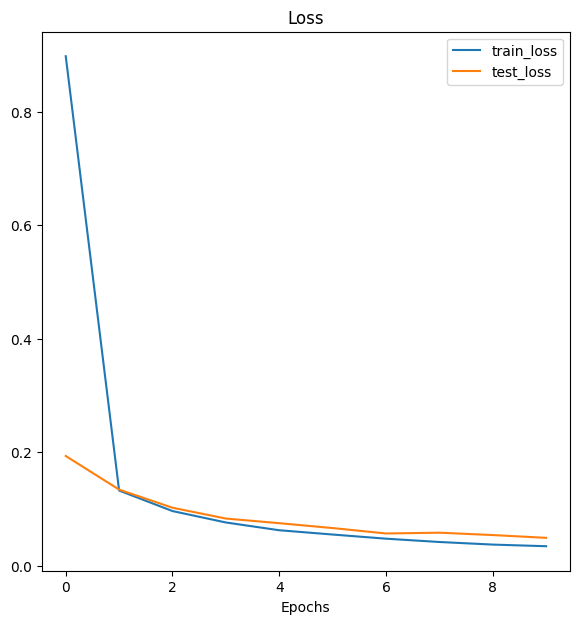

In [ ]:
plot_loss_curves(best_val_loss, best_sentence_level_model)

Бачимо, що з кожною наступною епохою тестова втрата збільшується, тому варто змінити швидкість навчання та відкорегувати інші гіперпараметри. Оскільки, це може суттєво збільшити час навчання, ми залишаємо поточно навчену мережу.

Завантажуємо модель

In [ ]:
save_model(model_500_10_context, filepath="best_model_data_500_10_context.pth")

Модель збережено в best_model_data_500_10_context.pth


Вивантажуємо модель для перевірки на реченнях

In [ ]:
load_model(model_500_10_context, filepath="best_model_data_500_10_context.pth", device=device)
model_500_10_context.eval()
print("Model is loaded successfully")

Модель завантажено з best_model_data_500_10_context.pth
Model is loaded successfully


In [ ]:
sentence_level_model_pos_tagger_context = POSTagger(
    model= model_500_10_context,
    char2id=char_vocab,
    id2label={v: k for k, v in pos_vocab.items()},
    max_sent_len=max_sent_len,
    max_token_len=max_token_len
)

results = sentence_level_model_pos_tagger_context(test_sentences, device=device)

# Виведення результатів
for sentence_result in results:
    print(" ".join(f"{token}_{tag}" for token, tag in sentence_result))

Сорок_PROPN сорок_NOUN прилетіли_VERB на_ADP дерево._NOUN
Раз_ADV у_ADP раз_NOUN він_PRON перевіряв_VERB завдання._NOUN
Замок_ADV замкнув_VERB двері._NOUN
Ніс_NOUN ніс_PRON кошик_DET до_ADP хати._X
Брати_VERB брати_VERB книжки_NOUN не_PART хотіли._X
Мати_VERB мати_VERB не_PART могла_VERB прийти._X
Лук_ADV на_ADP городі_NOUN виріс,_NOUN а_CCONJ він_PRON вправно_ADV луком_NOUN стріляв._NOUN
Став_VERB став_VERB на_ADP березі,_NOUN милуючись_VERB водою._X


Контекстна модель (SentenceLevelPOSTagger) здатна краще розрізняти омонімічні слова, використовуючи оточення слова у реченні. Наприклад, у реченні «Сорок сорок прилетіли на дерево» перший «сорок» правильно визначений як власна назва чи числівник (PROPN), а другий – як іменник (NOUN). Аналогічно, у реченні «Раз у раз він перевіряв завдання» прислівникове і числівникове значення «раз» відокремлено, що демонструє врахування контексту.
Проте у неї є і суттєві помилки, особливо у складних синтаксичних конструкціях: слова як «Ніс», «Брати», «Мати» та «Став» отримують тег невизначеного. Деякі омоніми також можуть отримувати неприродні теги, наприклад, «Лук» позначено як прислівник (ADV), хоча контекст дозволяв точніше визначення.
Це можливе через неточне налаштування параметрів моделі та зменшену вибріку для тренування та валідації та обмеженій кількості епох.

